# Single-Node Carbon-Aware Scheduler Visualization

This notebook visualizes power consumption, energy usage, and carbon emissions for single-node training experiments with various parallelism strategies.

In [1]:
# imports
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

COLORS = {
    "dp": "#2196F3", "tp": "#4CAF50", "pp": "#FF9800",
    "mixed": "#9C27B0", "schedule": "#E91E63",
}


In [2]:
# settings
BASE = os.getcwd()
MODEL_NAME = "llama_1b"
DATA_DIR = os.path.join(BASE, "power_logs", MODEL_NAME)
PLOTS_DIR = os.path.join(BASE, "plots", MODEL_NAME)
os.makedirs(PLOTS_DIR, exist_ok=True)
print(f"Reading power logs from: {DATA_DIR}")
print(f"Saving plots to: {PLOTS_DIR}")

INTERVAL_SECONDS = 0.5
TRAIN_ITERS = 200
GLOBAL_BATCH = 16
SEQ_LEN = 1024

A = [400, 100, 100]   # CI per period (gCO₂/kWh)
CI_FIXED = 400    # baseline constant


Reading power logs from: /afs/cs.pitt.edu/usr0/wat29/scheduling-carbon-aware-3d-parallelism/power_logs/llama_1b
Saving plots to: /afs/cs.pitt.edu/usr0/wat29/scheduling-carbon-aware-3d-parallelism/plots/llama_1b


In [3]:
# helpers
def load_power_csv(path):
    df = pd.read_csv(path)
    df.columns = [c.strip() for c in df.columns]
    if "time_step" not in df.columns:
        df.columns = ["timestamp", "total_power_W",
                      "GPU_0_W", "GPU_1_W", "GPU_2_W", "GPU_3_W"]
        df["time_step"] = 0
    return df


def get_ci_schedule_wallclock(n_samples, interval, A, schedule_duration_s):
    ci = np.full(n_samples, A[-1], dtype=float)
    period_s = schedule_duration_s / len(A)
    for i, c in enumerate(A):
        idx_start = max(0, min(int(i * period_s / interval), n_samples))
        idx_end   = max(0, min(int((i + 1) * period_s / interval), n_samples))
        ci[idx_start:idx_end] = c
    return ci


def compute_carbon(power_samples, ci_array, interval=0.5):
    energy_kwh = power_samples * interval / 3_600_000
    grams = energy_kwh * ci_array
    return np.cumsum(grams), grams.sum()


## Setup & Configuration

Load imports, configure plot style, and set analysis parameters.

In [4]:
# ci colors
_CI_CMAP = plt.cm.YlOrRd
_CI_NORM = None

def build_ci_norm(A):
    global _CI_NORM
    ci_min, ci_max = min(A), max(A)
    if ci_max == ci_min:
        _CI_NORM = mcolors.Normalize(vmin=ci_min * 0.9, vmax=ci_max * 1.1)
    else:
        _CI_NORM = mcolors.Normalize(vmin=ci_min, vmax=ci_max)

def ci_to_color(ci_val):
    if _CI_NORM is None:
        raise RuntimeError("Call build_ci_norm(A) first.")
    return _CI_CMAP(_CI_NORM(ci_val))

def ci_label(ci_val, A):
    ci_min, ci_max = min(A), max(A)
    if ci_val == ci_max and ci_val != ci_min:
        return f"{ci_val} g/kWh (high)"
    if ci_val == ci_min and ci_val != ci_max:
        return f"{ci_val} g/kWh (low)"
    return f"{ci_val} g/kWh"

build_ci_norm(A)

def add_ci_colorbar(fig, ax, A, label="CI (gCO₂/kWh)"):
    sm = plt.cm.ScalarMappable(cmap=_CI_CMAP, norm=_CI_NORM)
    sm.set_array([])
    cb = fig.colorbar(sm, ax=ax, orientation="vertical",
                      fraction=0.03, pad=0.02, shrink=0.75)
    cb.set_label(label, fontsize=8)
    cb.set_ticks(sorted(set(A)))
    cb.set_ticklabels([ci_label(c, A) for c in sorted(set(A))])
    return cb


def _classify(cfg):
    if cfg["is_schedule"]:
        return "schedule"
    dims_gt1 = sum(1 for d in (cfg["tp"], cfg["pp"], cfg["dp"]) if d > 1)
    if dims_gt1 >= 2: return "mixed"
    if cfg["tp"] > 1: return "tp"
    if cfg["pp"] > 1: return "pp"
    return "dp"


def _label(cfg):
    if cfg["is_schedule"]:
        return "Hybrid\nSchedule"
    parts = []
    if cfg["tp"] > 1: parts.append(f"TP={cfg['tp']}")
    if cfg["pp"] > 1: parts.append(f"PP={cfg['pp']}")
    if cfg["dp"] > 1: parts.append(f"DP={cfg['dp']}")
    return ",".join(parts) if parts else "DP=1"


def annotate_ci_periods(ax, A, schedule_duration_s, y_label_frac=0.04):
    period_s = schedule_duration_s / len(A)
    ylo, yhi = ax.get_ylim()
    y_text = ylo + (yhi - ylo) * y_label_frac
    for i, c in enumerate(A):
        x0, x1 = i * period_s, (i + 1) * period_s
        ax.axvspan(x0, x1, alpha=0.18, color=ci_to_color(c), zorder=0)
        ax.text((x0 + x1) / 2, y_text, ci_label(c, A),
                ha="center", va="bottom", fontsize=8,
                fontweight="bold", color=ci_to_color(c), alpha=0.85)
    xlim = ax.get_xlim()
    if xlim[1] > schedule_duration_s:
        ax.axvspan(schedule_duration_s, xlim[1], alpha=0.10,
                   color=ci_to_color(A[-1]), zorder=0)


In [5]:
# load csvs compute
all_possible_configs = {
    "tp1_pp1_dp4": {"tp": 1, "pp": 1, "dp": 4, "file": "elastic_tp1_pp1_dp4_power.csv", "is_schedule": False},
    "tp4_pp1_dp1": {"tp": 4, "pp": 1, "dp": 1, "file": "elastic_tp4_pp1_dp1_power.csv", "is_schedule": False},
    "tp1_pp4_dp1": {"tp": 1, "pp": 4, "dp": 1, "file": "elastic_tp1_pp4_dp1_power.csv", "is_schedule": False},
    "tp2_pp2_dp1": {"tp": 2, "pp": 2, "dp": 1, "file": "elastic_tp2_pp2_dp1_power.csv", "is_schedule": False},
    "tp2_pp1_dp2": {"tp": 2, "pp": 1, "dp": 2, "file": "elastic_tp2_pp1_dp2_power.csv", "is_schedule": False},
    "tp1_pp2_dp2": {"tp": 1, "pp": 2, "dp": 2, "file": "elastic_tp1_pp2_dp2_power.csv", "is_schedule": False},
}

schedule_configs_def = {
    "hybrid_schedule": {
        "tp": None, "pp": None, "dp": None,
        "file": "elastic_example_schedule_power.csv",
        "is_schedule": True,
    },
}

configs = {}
skipped = []

for name, cfg in {**all_possible_configs, **schedule_configs_def}.items():
    path = os.path.join(DATA_DIR, cfg["file"])
    if not os.path.exists(path):
        skipped.append(name)
        continue
    df = load_power_csv(path)
    if len(df) < 2:
        skipped.append(name)
        continue
    warmup = int(len(df) * 0.2)
    steady = df.iloc[warmup:]
    cfg["avg_power"] = df["total_power_W"].mean()
    cfg["steady_avg_power"] = steady["total_power_W"].mean()
    cfg["peak_power"] = df["total_power_W"].max()
    cfg["df"] = df
    configs[name] = cfg
    tag = " [SCHED]" if cfg["is_schedule"] else ""
    print(f"{name}{tag}: avg={cfg['avg_power']:.1f}W  "
          f"steady={cfg['steady_avg_power']:.1f}W  samples={len(df)}")

if skipped:
    print(f"\nSkipped: {', '.join(skipped)}")

static_configs = {k: v for k, v in configs.items() if not v["is_schedule"]}
sched_configs  = {k: v for k, v in configs.items() if v["is_schedule"]}
n_configs = len(configs)
all_configs = [(_label(cfg), _classify(cfg), cfg) for _, cfg in configs.items()]


tp1_pp1_dp4: avg=772.4W  steady=872.0W  samples=847
tp4_pp1_dp1: avg=540.1W  steady=562.1W  samples=1920
tp1_pp4_dp1: avg=672.8W  steady=734.3W  samples=1044
tp2_pp2_dp1: avg=579.3W  steady=615.4W  samples=1456
tp2_pp1_dp2: avg=665.4W  steady=725.6W  samples=1118
tp1_pp2_dp2: avg=757.8W  steady=853.0W  samples=868
hybrid_schedule [SCHED]: avg=584.0W  steady=628.9W  samples=1495


## Single-Model Analysis

Load power logs for various parallelism configurations (DP, TP, PP, mixed) and compute key metrics.

In [6]:
# 4b derive ci
if not configs:
    raise RuntimeError("No configs loaded — cannot derive schedule duration.")

CI_SCHEDULE_DURATION_S = max(len(cfg["df"]) for cfg in configs.values()) * INTERVAL_SECONDS
slowest = max(configs.items(), key=lambda kv: len(kv[1]["df"]))[0]
print(f"\nCI schedule duration (derived): {CI_SCHEDULE_DURATION_S:.1f}s "
      f"(slowest = {slowest})")
print(f"Each of the {len(A)} periods covers "
      f"{CI_SCHEDULE_DURATION_S / len(A):.1f}s of wall-clock time.")



CI schedule duration (derived): 960.0s (slowest = tp4_pp1_dp1)
Each of the 3 periods covers 320.0s of wall-clock time.


In [7]:
# metrics
total_tokens = TRAIN_ITERS * GLOBAL_BATCH * SEQ_LEN

print(f"\n{'Label':20s} | {'Time':>6s} | {'Power':>7s} | "
      f"{'Energy':>7s} | {'C_fix':>7s} | {'C_var':>7s} | {'Tput':>9s}")
print("-" * 82)

for label, _, cfg in all_configs:
    power = cfg["df"]["total_power_W"].to_numpy()
    n = len(power)
    total_time_s = n * INTERVAL_SECONDS
    cfg["train_time_s"] = total_time_s
    cfg["total_time_s"] = total_time_s
    cfg["avg_power_w"] = power.mean()
    cfg["total_energy_wh"] = power.sum() * INTERVAL_SECONDS / 3600
    cfg["tokens_per_sec"] = total_tokens / total_time_s

    _, cfg["carbon_fixed_g"] = compute_carbon(power, np.full(n, CI_FIXED))
    ci_var = get_ci_schedule_wallclock(n, INTERVAL_SECONDS, A, CI_SCHEDULE_DURATION_S)
    _, cfg["carbon_varying_g"] = compute_carbon(power, ci_var)

    tag = " ★" if cfg["is_schedule"] else ""
    print(f"{label.replace(chr(10),' '):20s} | {total_time_s:5.1f}s | "
          f"{cfg['avg_power_w']:6.1f}W | {cfg['total_energy_wh']:6.2f}Wh | "
          f"{cfg['carbon_fixed_g']:5.1f}g | {cfg['carbon_varying_g']:5.1f}g | "
          f"{cfg['tokens_per_sec']:7.1f} t/s{tag}")



Label                |   Time |   Power |  Energy |   C_fix |   C_var |      Tput
----------------------------------------------------------------------------------
DP=4                 | 423.5s |  772.4W |  90.86Wh |  36.3g |  29.0g |  7737.4 t/s
TP=4                 | 960.0s |  540.1W | 144.02Wh |  57.6g |  27.7g |  3413.3 t/s
PP=4                 | 522.0s |  672.8W |  97.55Wh |  39.0g |  26.7g |  6277.4 t/s
TP=2,PP=2            | 728.0s |  579.3W | 117.14Wh |  46.9g |  26.0g |  4501.1 t/s
TP=2,DP=2            | 559.0s |  665.4W | 103.32Wh |  41.3g |  26.9g |  5861.9 t/s
PP=2,DP=2            | 434.0s |  757.8W |  91.36Wh |  36.5g |  28.6g |  7550.2 t/s
Hybrid Schedule      | 747.5s |  584.0W | 121.26Wh |  48.5g |  25.1g |  4383.7 t/s ★


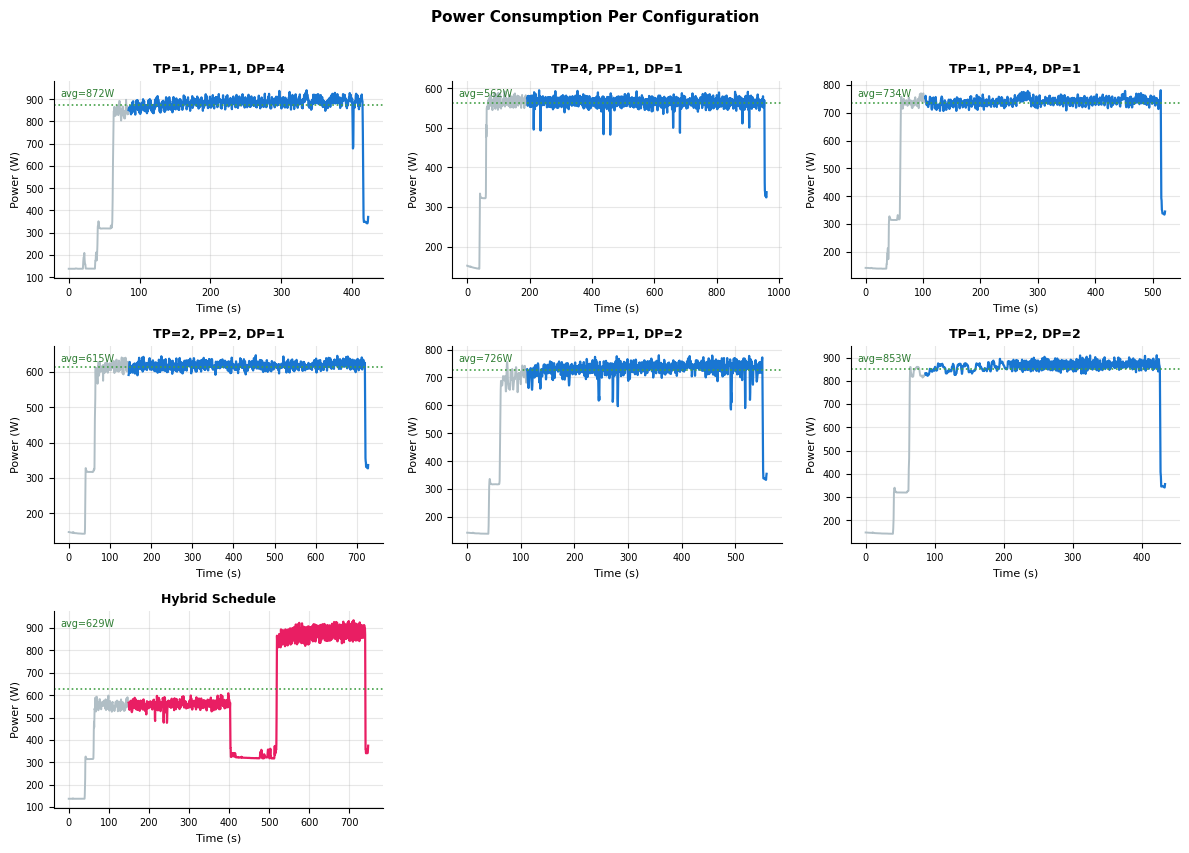

In [8]:
# power traces config
if n_configs > 0:
    ncols = min(3, n_configs)
    nrows = (n_configs + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(12, 2.8 * nrows))
    axes = np.atleast_1d(axes).flatten()

    for ax, (name, cfg) in zip(axes, configs.items()):
        df = cfg["df"]
        warmup_idx = int(len(df) * 0.2)
        x = np.arange(len(df)) * INTERVAL_SECONDS
        y = df["total_power_W"].to_numpy()

        ax.plot(x[:warmup_idx], y[:warmup_idx], color="#B0BEC5", linewidth=1.4)
        ax.plot(x[warmup_idx:], y[warmup_idx:],
                color=COLORS["schedule"] if cfg["is_schedule"] else "#1976D2",
                linewidth=1.6)
        ax.axhline(cfg["steady_avg_power"], color="#43A047", linestyle=":", linewidth=1.2)

        if cfg["is_schedule"]:
            title = "Hybrid Schedule"
            steps = df["time_step"].to_numpy()
            for j in range(1, len(steps)):
                if steps[j] < steps[j-1] and steps[j-1] > 0:
                    ax.axvline(x[j], color="#FF9800", linestyle="-.", linewidth=0.8, alpha=0.7)
        else:
            title = f"TP={cfg['tp']}, PP={cfg['pp']}, DP={cfg['dp']}"

        ax.set_title(title, fontsize=9, fontweight="bold")
        ax.set_xlabel("Time (s)", fontsize=8)
        ax.set_ylabel("Power (W)", fontsize=8)
        ax.tick_params(labelsize=7)
        ax.text(0.02, 0.92, f"avg={cfg['steady_avg_power']:.0f}W",
                transform=ax.transAxes, fontsize=7, color="#2E7D32")

    for ax in axes[n_configs:]:
        ax.set_visible(False)

    fig.suptitle("Power Consumption Per Configuration", fontsize=11, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph0_power_trends.png"), dpi=150, bbox_inches="tight")
    plt.show()


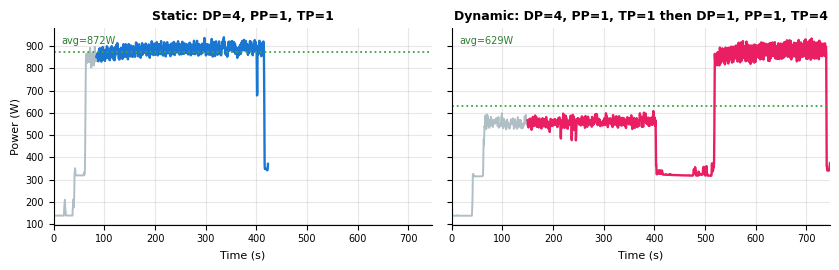

In [35]:
# power trace figure: static DP=4 vs dynamic strategy
static_key = None
dynamic_key = None

for name, cfg in configs.items():
    if (
        not cfg.get("is_schedule", False)
        and cfg.get("dp") == 4
        and cfg.get("pp") == 1
        and cfg.get("tp") == 1
    ):
        static_key = name

    if cfg.get("is_schedule", False):
        dynamic_key = name

if static_key is None:
    raise ValueError("Could not find static strategy with DP=4, PP=1, TP=1")

if dynamic_key is None:
    raise ValueError("Could not find dynamic strategy where cfg['is_schedule'] is True")

schedule_color = COLORS.get("schedule", "#D81B60") if "COLORS" in globals() else "#D81B60"

selected = [
    ("Static: DP=4, PP=1, TP=1", configs[static_key], "#1976D2"),
    ("Dynamic: DP=4, PP=1, TP=1 then DP=1, PP=1, TP=4", configs[dynamic_key], schedule_color),
]

# Precompute traces so both panels use identical x/y limits.
traces = []
for title, cfg, color in selected:
    df = cfg["df"]
    warmup_idx = int(len(df) * 0.2)

    x = np.arange(len(df)) * INTERVAL_SECONDS
    y = df["total_power_W"].to_numpy()

    traces.append({
        "title": title,
        "cfg": cfg,
        "df": df,
        "warmup_idx": warmup_idx,
        "x": x,
        "y": y,
        "color": color,
    })

x_max = max(trace["x"][-1] for trace in traces)
y_min = min(np.nanmin(trace["y"]) for trace in traces)
y_max = max(np.nanmax(trace["y"]) for trace in traces)
y_pad = 0.05 * (y_max - y_min) if y_max > y_min else 10

fig, axes = plt.subplots(
    1,
    2,
    figsize=(8.5, 2.8),
    sharex=True,
    sharey=True,
)

for ax, trace in zip(axes, traces):
    cfg = trace["cfg"]
    df = trace["df"]
    x = trace["x"]
    y = trace["y"]
    warmup_idx = trace["warmup_idx"]

    # Warmup region
    ax.plot(
        x[:warmup_idx],
        y[:warmup_idx],
        color="#B0BEC5",
        linewidth=1.4,
        label="Warmup",
    )

    # Steady region
    ax.plot(
        x[warmup_idx:],
        y[warmup_idx:],
        color=trace["color"],
        linewidth=1.7,
        label="Measured power",
    )

    # Steady-state average
    ax.axhline(
        cfg["steady_avg_power"],
        color="#43A047",
        linestyle=":",
        linewidth=1.3,
        label="Steady avg.",
    )

    # Mark dynamic strategy switches.
    if cfg.get("is_schedule", False):
        steps = df["time_step"].to_numpy()

        for j in range(1, len(steps)):
            if steps[j] < steps[j - 1] and steps[j - 1] > 0:
                ax.axvline(
                    x[j],
                    color="#FF9800",
                    linestyle="-.",
                    linewidth=0.9,
                    alpha=0.75,
                )

    ax.set_title(trace["title"], fontsize=9, fontweight="bold")
    ax.set_xlabel("Time (s)", fontsize=8)
    ax.tick_params(labelsize=7)

    ax.text(
        0.02,
        0.92,
        f"avg={cfg['steady_avg_power']:.0f}W",
        transform=ax.transAxes,
        fontsize=7,
        color="#2E7D32",
    )

    # Force identical axes across both plots.
    ax.set_xlim(0, x_max)
    ax.set_ylim(y_min - y_pad, y_max + y_pad)

axes[0].set_ylabel("Power (W)", fontsize=8)

fig.align_xlabels(axes)
fig.align_ylabels(axes)

plt.tight_layout()
plt.savefig(
    os.path.join(PLOTS_DIR, "graph_static_vs_dynamic_power.png"),
    dpi=300,
    bbox_inches="tight",
)
plt.show()

### Power Traces

Visualize power consumption over time for each configuration during training.


CI SCHEDULE:  A = [400, 100, 100] gCO₂/kWh over 960s
  Period 1: 0–320s → 400 g/kWh (high)
  Period 2: 320–640s → 100 g/kWh (low)
  Period 3: 640–960s → 100 g/kWh (low)
Fixed baseline: 400 gCO₂/kWh


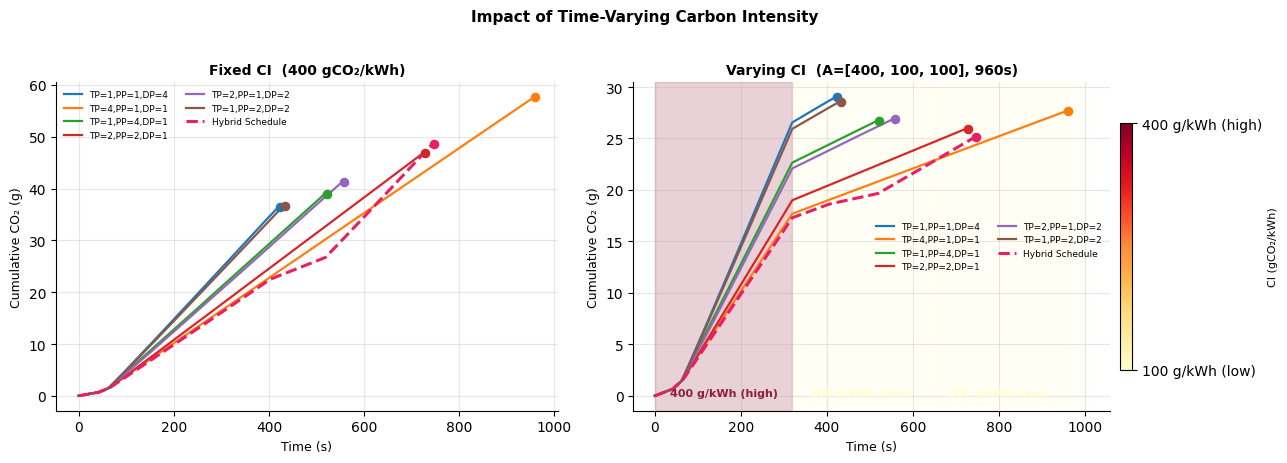

In [9]:
# fixed vs varying
print("\n" + "=" * 72)
print(f"CI SCHEDULE:  A = {A} gCO₂/kWh over {CI_SCHEDULE_DURATION_S:.0f}s")
period_s = CI_SCHEDULE_DURATION_S / len(A)
for i, c in enumerate(A):
    print(f"  Period {i+1}: {i*period_s:.0f}–{(i+1)*period_s:.0f}s → {ci_label(c, A)}")
print(f"Fixed baseline: {CI_FIXED} gCO₂/kWh")
print("=" * 72)

if n_configs > 0:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    for ax, use_varying in zip(axes, [False, True]):
        for name, cfg in configs.items():
            power = cfg["df"]["total_power_W"].to_numpy()
            n = len(power)
            ci = (get_ci_schedule_wallclock(n, INTERVAL_SECONDS, A, CI_SCHEDULE_DURATION_S)
                  if use_varying else np.full(n, CI_FIXED))
            cum, _ = compute_carbon(power, ci)
            x = np.arange(n) * INTERVAL_SECONDS

            style = {"linewidth": 2.2, "linestyle": "--"} if cfg["is_schedule"] else {"linewidth": 1.6}
            lbl = "Hybrid Schedule" if cfg["is_schedule"] else \
                  f"TP={cfg['tp']},PP={cfg['pp']},DP={cfg['dp']}"
            color = COLORS["schedule"] if cfg["is_schedule"] else None
            ax.plot(x, cum, label=lbl, color=color, **style)
            ax.scatter(x[-1], cum[-1], s=35, zorder=3, color=color)

        if use_varying:
            annotate_ci_periods(ax, A, CI_SCHEDULE_DURATION_S)
            ax.set_title(f"Varying CI  (A={A}, {CI_SCHEDULE_DURATION_S:.0f}s)",
                         fontsize=10, fontweight="bold")
            add_ci_colorbar(fig, ax, A)
        else:
            ax.set_title(f"Fixed CI  ({CI_FIXED} gCO₂/kWh)", fontsize=10, fontweight="bold")

        ax.set_xlabel("Time (s)", fontsize=9)
        ax.set_ylabel("Cumulative CO₂ (g)", fontsize=9)
        ax.legend(fontsize=6.5, ncol=2, frameon=False)

    plt.suptitle("Impact of Time-Varying Carbon Intensity",
                 fontsize=11, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph_carbon_varying_ci.png"),
                dpi=150, bbox_inches="tight")
    plt.show()


### Carbon Emissions: Fixed vs Time-Varying CI

Compare cumulative carbon emissions under fixed CI (baseline) vs time-varying CI schedule.

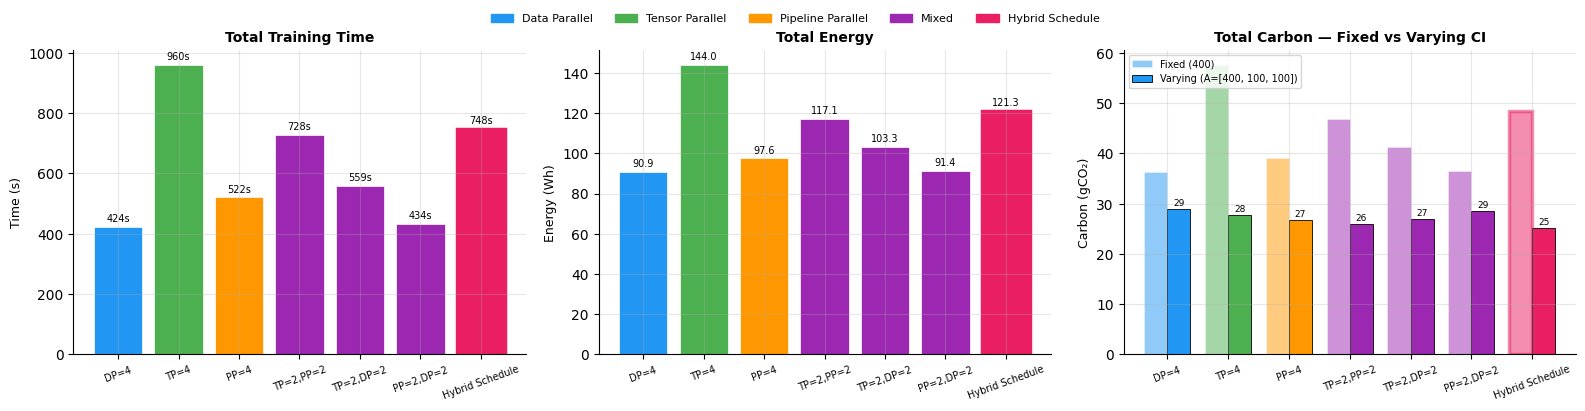

In [10]:
# compact bar chart
patches = [
    mpatches.Patch(color=COLORS["dp"],       label="Data Parallel"),
    mpatches.Patch(color=COLORS["tp"],       label="Tensor Parallel"),
    mpatches.Patch(color=COLORS["pp"],       label="Pipeline Parallel"),
    mpatches.Patch(color=COLORS["mixed"],    label="Mixed"),
    mpatches.Patch(color=COLORS["schedule"], label="Hybrid Schedule"),
]

if all_configs:
    labels_bar = [c[0].replace("\n", " ") for c in all_configs]
    colors_bar = [COLORS[c[1]] for c in all_configs]
    time_vals      = [c[2]["train_time_s"]     for c in all_configs]
    energy_vals    = [c[2]["total_energy_wh"]  for c in all_configs]
    carbon_fixed   = [c[2]["carbon_fixed_g"]   for c in all_configs]
    carbon_varying = [c[2]["carbon_varying_g"] for c in all_configs]
    is_sched       = [c[2]["is_schedule"]      for c in all_configs]

    edge_colors = ["#E91E63" if s else "white" for s in is_sched]
    edge_widths = [2.5 if s else 0.5 for s in is_sched]

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    # panel 1: total time
    ax = axes[0]
    ax.bar(labels_bar, time_vals, color=colors_bar,
           edgecolor=edge_colors, linewidth=edge_widths)
    for i, v in enumerate(time_vals):
        ax.text(i, v + max(time_vals) * 0.01, f"{v:.0f}s",
                ha="center", va="bottom", fontsize=7)
    ax.set_ylabel("Time (s)", fontsize=9)
    ax.set_title("Total Training Time", fontsize=10, fontweight="bold")
    ax.tick_params(axis="x", labelsize=7, rotation=20)

    # panel 2: total energy
    ax = axes[1]
    ax.bar(labels_bar, energy_vals, color=colors_bar,
           edgecolor=edge_colors, linewidth=edge_widths)
    for i, v in enumerate(energy_vals):
        ax.text(i, v + max(energy_vals) * 0.01, f"{v:.1f}",
                ha="center", va="bottom", fontsize=7)
    ax.set_ylabel("Energy (Wh)", fontsize=9)
    ax.set_title("Total Energy", fontsize=10, fontweight="bold")
    ax.tick_params(axis="x", labelsize=7, rotation=20)

    # panel 3: carbon fixed vs varying
    ax = axes[2]
    x = np.arange(len(labels_bar))
    width = 0.38
    ax.bar(x - width/2, carbon_fixed, width, color=colors_bar,
           alpha=0.5, edgecolor=edge_colors, linewidth=edge_widths,
           label=f"Fixed ({CI_FIXED})")
    ax.bar(x + width/2, carbon_varying, width, color=colors_bar,
           edgecolor="black", linewidth=0.6,
           label=f"Varying (A={A})")
    for xi, vv in zip(x, carbon_varying):
        ax.text(xi + width/2, vv + max(carbon_varying) * 0.01,
                f"{vv:.0f}", ha="center", va="bottom", fontsize=6.5)
    ax.set_ylabel("Carbon (gCO₂)", fontsize=9)
    ax.set_title("Total Carbon — Fixed vs Varying CI", fontsize=10, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(labels_bar, fontsize=7, rotation=20)
    ax.legend(fontsize=7, loc="upper left")

    fig.legend(handles=patches, fontsize=8, ncol=5,
               loc="upper center", bbox_to_anchor=(0.5, 1.03), frameon=False)
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph_metrics_overview.png"),
                dpi=150, bbox_inches="tight")
    plt.show()


### Metrics Overview

Summary bar charts: training time, energy, and carbon emissions comparison.

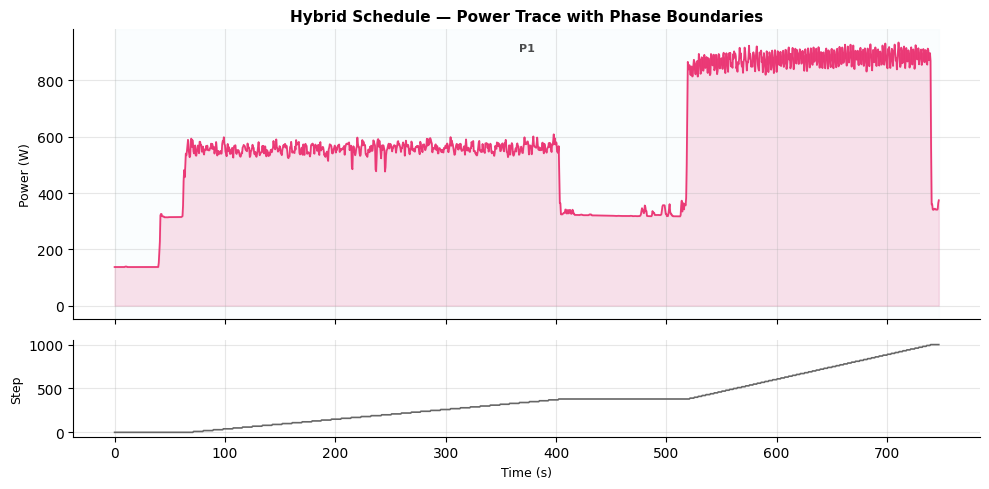

In [11]:
# schedule detail power
for name, cfg in sched_configs.items():
    df = cfg["df"]
    x = np.arange(len(df)) * INTERVAL_SECONDS
    y = df["total_power_W"].to_numpy()
    steps = df["time_step"].to_numpy()

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5), sharex=True,
                                    gridspec_kw={"height_ratios": [3, 1]})

    ax1.plot(x, y, color=COLORS["schedule"], linewidth=1.3, alpha=0.85)
    ax1.fill_between(x, y, alpha=0.15, color=COLORS["schedule"])
    ax1.set_ylabel("Power (W)", fontsize=9)
    ax1.set_title("Hybrid Schedule — Power Trace with Phase Boundaries",
                  fontsize=11, fontweight="bold")

    phase_colors = ["#E3F2FD", "#E8F5E9", "#FFF3E0", "#F3E5F5",
                    "#FCE4EC", "#E0F7FA", "#FFF9C4"]
    boundaries = [0]
    for j in range(1, len(steps)):
        if steps[j] < steps[j-1] and steps[j-1] > 0:
            boundaries.append(j)
    boundaries.append(len(df))

    for p_idx in range(len(boundaries) - 1):
        s_idx = boundaries[p_idx]
        e_idx = boundaries[p_idx + 1]
        if s_idx < len(x) and e_idx <= len(x):
            ax1.axvspan(x[s_idx], x[min(e_idx - 1, len(x) - 1)],
                        alpha=0.15, color=phase_colors[p_idx % len(phase_colors)])
            mid_x = (x[s_idx] + x[min(e_idx - 1, len(x) - 1)]) / 2
            ax1.text(mid_x, ax1.get_ylim()[1] * 0.95, f"P{p_idx + 1}",
                     ha="center", va="top", fontsize=8, fontweight="bold", alpha=0.7)

    ax2.plot(x, steps, color="#666", linewidth=1.2)
    ax2.set_xlabel("Time (s)", fontsize=9)
    ax2.set_ylabel("Step", fontsize=9)

    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph_schedule_detailed.png"),
                dpi=150, bbox_inches="tight")
    plt.show()


### Schedule Analysis

Detailed power trace with phase boundaries and step markers for hybrid schedule.

In [12]:
# summary
if all_configs:
    summary_rows = []
    for label, _, cfg in all_configs:
        summary_rows.append({
            "Config":           label.replace("\n", " "),
            "Type":             "Schedule" if cfg["is_schedule"] else "Static",
            "Time(s)":          round(cfg["train_time_s"], 1),
            "Avg Power(W)":     round(cfg["avg_power_w"], 1),
            "Energy(Wh)":       round(cfg["total_energy_wh"], 2),
            f"C_Fixed@{CI_FIXED}(g)": round(cfg["carbon_fixed_g"], 2),
            "C_Vary(g)":        round(cfg["carbon_varying_g"], 2),
            "Tput(tok/s)":      round(cfg["tokens_per_sec"], 1),
        })

    summary_df = pd.DataFrame(summary_rows)
    print("\n" + "=" * 95)
    print("SUMMARY TABLE")
    print("=" * 95)
    print(summary_df.to_string(index=False))
    summary_df.to_csv(os.path.join(PLOTS_DIR, "summary_table.csv"), index=False)
    print(f"\nSaved: {os.path.join(PLOTS_DIR, 'summary_table.csv')}")


SUMMARY TABLE
         Config     Type  Time(s)  Avg Power(W)  Energy(Wh)  C_Fixed@400(g)  C_Vary(g)  Tput(tok/s)
           DP=4   Static    423.5         772.4       90.86           36.34      29.00       7737.4
           TP=4   Static    960.0         540.1      144.02           57.61      27.67       3413.3
           PP=4   Static    522.0         672.8       97.55           39.02      26.75       6277.4
      TP=2,PP=2   Static    728.0         579.3      117.14           46.86      25.96       4501.1
      TP=2,DP=2   Static    559.0         665.4      103.32           41.33      26.90       5861.9
      PP=2,DP=2   Static    434.0         757.8       91.36           36.54      28.59       7550.2
Hybrid Schedule Schedule    747.5         584.0      121.26           48.50      25.10       4383.7

Saved: /afs/cs.pitt.edu/usr0/wat29/scheduling-carbon-aware-3d-parallelism/plots/llama_1b/summary_table.csv


In [13]:
# model savings
MODEL_PARAMS_M = {
    "gpt2":         124,
    "gpt2_medium":  355,
    "gpt2_large":   774,
    "llama_1b":    1100,
    "llama_2b":    2000,
    "llama_3b":    3000,
}

FAMILIES = {
    "gpt2":  {
        "models": ["gpt2", "gpt2_medium", "gpt2_large"],
        "A":      [600, 300, 300],
        "title":  "GPT-2 family",
    },
    "llama": {
        "models": ["llama_1b", "llama_2b", "llama_3b"],
        "A":      [400, 100, 100],
        "title":  "Llama family",
    },
}

STATIC_FILES = [
    "elastic_tp1_pp1_dp4_power.csv",
    "elastic_tp4_pp1_dp1_power.csv",
    "elastic_tp1_pp4_dp1_power.csv",
    "elastic_tp2_pp2_dp1_power.csv",
    "elastic_tp2_pp1_dp2_power.csv",
    "elastic_tp1_pp2_dp2_power.csv",
]
SCHEDULE_FILE = "elastic_example_schedule_power.csv"

CROSS_PLOTS_DIR = os.path.join(BASE, "plots", "cross_model")
os.makedirs(CROSS_PLOTS_DIR, exist_ok=True)


def _load_runs(ddir, files):
    out = {}
    for f in files:
        p = os.path.join(ddir, f)
        if not os.path.exists(p):
            continue
        df = load_power_csv(p)
        if len(df) >= 2:
            out[f] = df
    return out


def _carbon_varying(df, A_family, schedule_duration_s):
    power = df["total_power_W"].to_numpy()
    ci = get_ci_schedule_wallclock(len(power), INTERVAL_SECONDS,
                                   A_family, schedule_duration_s)
    _, total = compute_carbon(power, ci, INTERVAL_SECONDS)
    return total


def _collect_family_rows(models, A_family):
    rows = []
    for m in sorted(models, key=lambda x: MODEL_PARAMS_M.get(x, 0)):
        ddir = os.path.join(BASE, "power_logs", m)
        if not os.path.isdir(ddir):
            print(f"[skip] {m}: no directory")
            continue

        static_runs = _load_runs(ddir, STATIC_FILES)
        sched_runs  = _load_runs(ddir, [SCHEDULE_FILE])
        if not static_runs or not sched_runs:
            print(f"[skip] {m}: missing runs")
            continue

        all_runs = {**static_runs, **sched_runs}
        sched_dur_s = max(len(df) for df in all_runs.values()) * INTERVAL_SECONDS

        static_carbons = [_carbon_varying(df, A_family, sched_dur_s)
                          for df in static_runs.values()]
        sched_carbon   = _carbon_varying(next(iter(sched_runs.values())),
                                         A_family, sched_dur_s)

        best_fixed = min(static_carbons)
        saving_pct = (best_fixed - sched_carbon) / best_fixed * 100

        rows.append({
            "model":        m,
            "params_M":     MODEL_PARAMS_M.get(m, 0),
            "sched_dur_s":  sched_dur_s,
            "best_fixed_g": best_fixed,
            "schedule_g":   sched_carbon,
            "saving_pct":   saving_pct,
        })
        print(f"{m:15s} | window={sched_dur_s:6.0f}s | "
              f"best fixed={best_fixed:7.1f}g | schedule={sched_carbon:7.1f}g | "
              f"saved={saving_pct:+5.1f}%")
    return rows


def _plot_family(rows, A_family, title, outfile):
    if len(rows) < 2:
        print(f"[skip plot] {title}: need ≥2 models, got {len(rows)}")
        return
    params  = [r["params_M"]    for r in rows]
    savings = [r["saving_pct"]  for r in rows]
    names   = [r["model"]       for r in rows]
    windows = [r["sched_dur_s"] for r in rows]

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(params, savings, "o-", color=COLORS["schedule"],
            linewidth=2.5, markersize=11,
            markerfacecolor="white", markeredgewidth=2.5)
    for p, s, n, w in zip(params, savings, names, windows):
        ax.annotate(f"{n}\n{s:+.1f}%  ({w:.0f}s)", (p, s),
                    textcoords="offset points", xytext=(8, 6), fontsize=8)
    ax.axhline(0, color="gray", linestyle=":", alpha=0.6)
    ax.set_xscale("log")
    ax.set_xlabel("Model size (parameters, millions)", fontsize=11)
    ax.set_ylabel("Carbon saved by elastic schedule (%)", fontsize=11)
    ax.set_title(
        f"{title} — elastic savings vs model size\n"
        f"CI schedule A = {A_family}, window auto-sized per model",
        fontsize=11, fontweight="bold",
    )
    plt.tight_layout()
    plt.savefig(os.path.join(CROSS_PLOTS_DIR, outfile),
                dpi=150, bbox_inches="tight")
    plt.show()



── GPT-2 family  (A = [600, 300, 300]) ──
gpt2            | window=   550s | best fixed=   18.4g | schedule=   20.3g | saved=-10.0%
gpt2_medium     | window=  1280s | best fixed=   69.9g | schedule=   67.1g | saved= +4.1%
gpt2_large      | window=  2166s | best fixed=  119.4g | schedule=  123.8g | saved= -3.7%


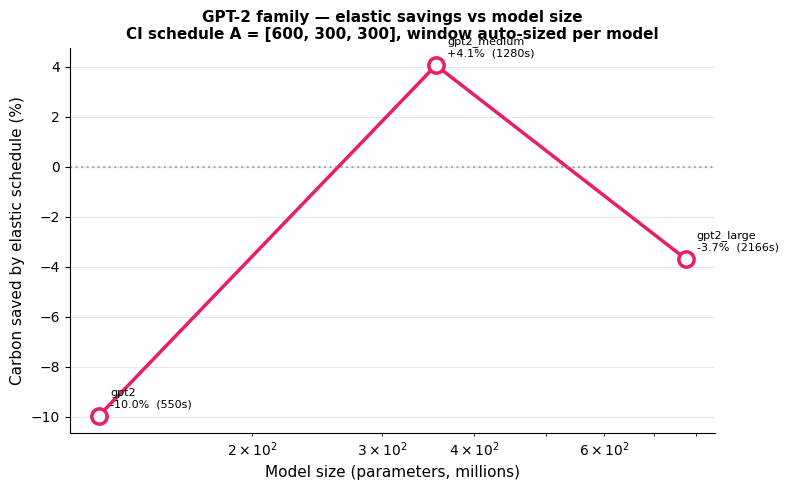


── Llama family  (A = [400, 100, 100]) ──
llama_1b        | window=   960s | best fixed=   26.0g | schedule=   25.1g | saved= +3.3%
llama_2b        | window=  1371s | best fixed=   42.7g | schedule=   40.9g | saved= +4.3%
llama_3b        | window=  1386s | best fixed=   50.8g | schedule=   46.5g | saved= +8.6%


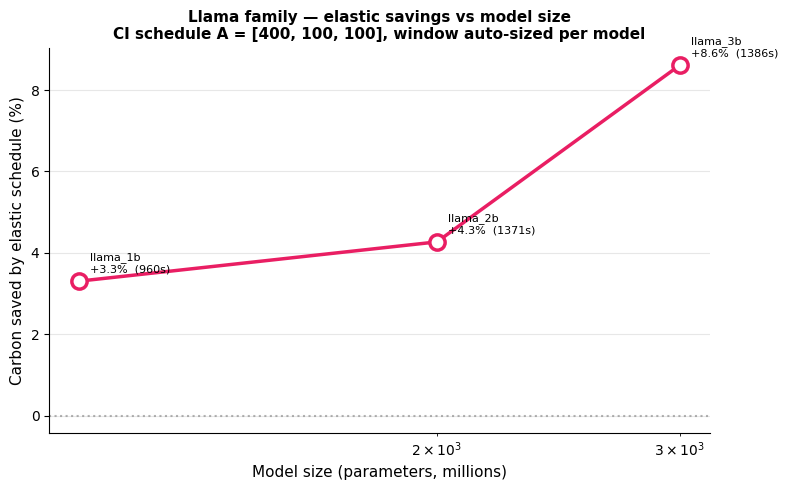

In [14]:
# run family
for family_key, fam in FAMILIES.items():
    print(f"\n── {fam['title']}  (A = {fam['A']}) ──")
    rows = _collect_family_rows(fam["models"], fam["A"])
    _plot_family(rows, fam["A"], fam["title"],
                 f"savings_vs_model_size_{family_key}.png")

## Cross-Model Analysis

Compare elastic scheduler savings across different model sizes and families (GPT-2, Llama).

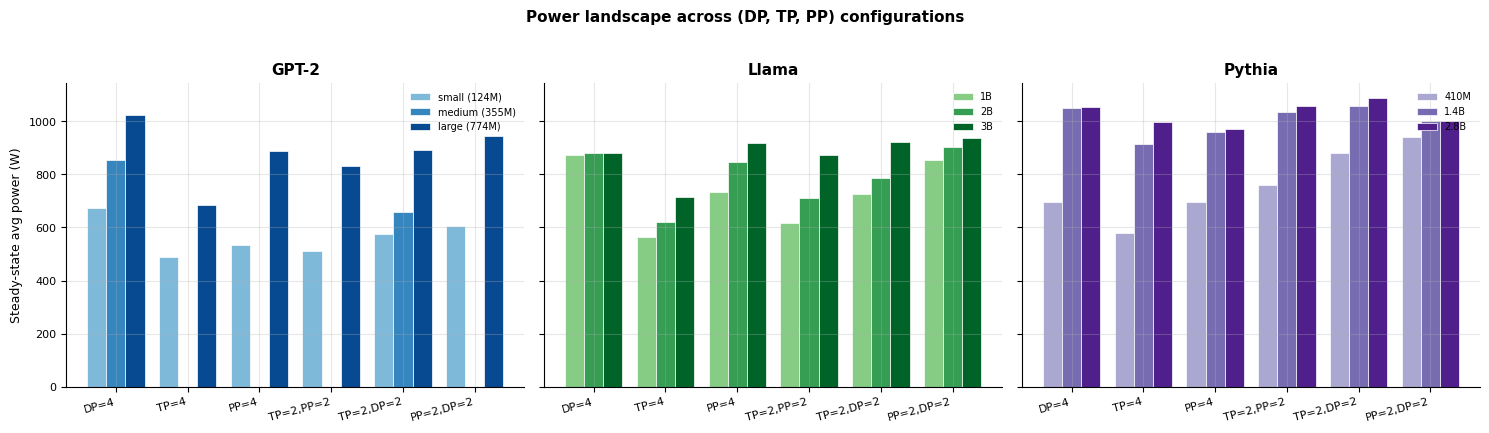


Saved: /afs/cs.pitt.edu/usr0/wat29/scheduling-carbon-aware-3d-parallelism/plots/cross_model/power_landscape_by_family.png

Family   | Size               |       DP=4 |       TP=4 |       PP=4 |  TP=2,PP=2 |  TP=2,DP=2 |  PP=2,DP=2
-----------------------------------------------------------------------------------------------------------
GPT-2    | small (124M)       |      672.1 |      488.2 |      533.9 |      512.0 |      575.8 |      604.5
GPT-2    | medium (355M)      |      855.4 |          — |          — |          — |      656.3 |          —
GPT-2    | large (774M)       |     1021.7 |      682.8 |      889.3 |      829.4 |      891.4 |      945.0
Llama    | 1B                 |      872.0 |      562.1 |      734.3 |      615.4 |      725.6 |      853.0
Llama    | 2B                 |      879.1 |      619.6 |      844.9 |      711.0 |      785.5 |      904.5
Llama    | 3B                 |      879.9 |      713.0 |      917.9 |      871.1 |      922.4 |      937.7
Pythia   | 4

In [15]:
# =====================================================================
# Power landscape plot
# =====================================================================
import os
import numpy as np
import matplotlib.pyplot as plt

CONFIG_ORDER = [
    ("elastic_tp1_pp1_dp4_power.csv", "DP=4"),
    ("elastic_tp4_pp1_dp1_power.csv", "TP=4"),
    ("elastic_tp1_pp4_dp1_power.csv", "PP=4"),
    ("elastic_tp2_pp2_dp1_power.csv", "TP=2,PP=2"),
    ("elastic_tp2_pp1_dp2_power.csv", "TP=2,DP=2"),
    ("elastic_tp1_pp2_dp2_power.csv", "PP=2,DP=2"),
]

POWER_LANDSCAPE_FAMILIES = {
    "GPT-2":  ["gpt2", "gpt2_medium", "gpt2_large"],
    "Llama":  ["llama_1b", "llama_2b", "llama_3b"],
    "Pythia": ["pythia_410m", "pythia_1_4b", "pythia_2_8b"],
}

SIZE_LABELS = {
    "gpt2": "small (124M)", "gpt2_medium": "medium (355M)", "gpt2_large": "large (774M)",
    "llama_1b": "1B", "llama_2b": "2B", "llama_3b": "3B",
    "pythia_410m": "410M", "pythia_1_4b": "1.4B", "pythia_2_8b": "2.8B",
}

FAMILY_CMAPS = {"GPT-2": plt.cm.Blues, "Llama": plt.cm.Greens, "Pythia": plt.cm.Purples}


# ---------------------------------------------------------------------
# Helpers
# ---------------------------------------------------------------------
def _steady_avg_power(path, warmup_frac=0.2):
    """Steady-state mean total power (W). Returns None if file missing/too short."""
    if not os.path.exists(path):
        return None
    df = load_power_csv(path)
    if len(df) < 5:
        return None
    warmup = int(len(df) * warmup_frac)
    return df["total_power_W"].iloc[warmup:].mean()


def diagnose_power_logs():
    """Print a per-cell status report so missing bars can be traced to a cause."""
    print(f"{'family':8s} {'model':14s} {'config':14s} status")
    print("-" * 80)
    for fam_name, models in POWER_LANDSCAPE_FAMILIES.items():
        for m in models:
            ddir = os.path.join(BASE, "power_logs", m)
            if not os.path.isdir(ddir):
                print(f"{fam_name:8s} {m:14s} {'(all)':14s} DIR MISSING: {ddir}")
                continue
            for fn, lbl in CONFIG_ORDER:
                path = os.path.join(ddir, fn)
                if not os.path.exists(path):
                    status = "FILE MISSING"
                else:
                    try:
                        df = load_power_csv(path)
                        if len(df) < 5:
                            status = f"TOO SHORT ({len(df)} rows)"
                        else:
                            status = (f"OK ({len(df)} rows, "
                                      f"mean={df['total_power_W'].mean():.1f}W)")
                    except Exception as e:
                        status = f"LOAD ERROR: {type(e).__name__}: {e}"
                print(f"{fam_name:8s} {m:14s} {lbl:14s} {status}")
            expected = {fn for fn, _ in CONFIG_ORDER}
            extra = sorted(set(os.listdir(ddir)) - expected)
            if extra:
                print(f"{'':8s} {m:14s} {'(extras)':14s} {extra}")


# ---------------------------------------------------------------------
# Collect data per family/model
# ---------------------------------------------------------------------
landscape_data = {}
for fam_name, models in POWER_LANDSCAPE_FAMILIES.items():
    fam = {}
    for m in models:
        ddir = os.path.join(BASE, "power_logs", m)
        if not os.path.isdir(ddir):
            continue
        powers = [_steady_avg_power(os.path.join(ddir, fn))
                  for fn, _ in CONFIG_ORDER]
        if any(p is not None for p in powers):
            fam[m] = powers
    if fam:
        landscape_data[fam_name] = fam


# ---------------------------------------------------------------------
# Plot
# ---------------------------------------------------------------------
if not landscape_data:
    print("No power logs found for any family — nothing to plot.")
else:
    n_fam = len(landscape_data)
    # sharey=True calibrates the y-axis identically across all family panels
    fig, axes = plt.subplots(
        1, n_fam,
        figsize=(5.0 * n_fam, 4.2),
        sharey=True,
    )
    axes = np.atleast_1d(axes)

    # Compute a common upper bound with a small headroom margin so bars
    # don't touch the top of any panel.
    global_max = max(
        p for fam in landscape_data.values()
        for ps in fam.values()
        for p in ps if p is not None
    )

    cfg_labels = [lbl for _, lbl in CONFIG_ORDER]
    x = np.arange(len(cfg_labels))

    for idx, (ax, (fam_name, fam)) in enumerate(zip(axes, landscape_data.items())):
        sizes = list(fam.keys())
        n_sizes = len(sizes)
        bar_w = 0.8 / max(n_sizes, 1)
        cmap = FAMILY_CMAPS.get(fam_name, plt.cm.Greys)
        shades = [cmap(0.45 + 0.45 * i / max(n_sizes - 1, 1)) for i in range(n_sizes)]

        for i, m in enumerate(sizes):
            powers = fam[m]
            offset = (i - (n_sizes - 1) / 2) * bar_w
            valid = [(xi + offset, p) for xi, p in zip(x, powers) if p is not None]
            if not valid:
                continue
            xs, ps = zip(*valid)
            ax.bar(xs, ps, bar_w, color=shades[i], edgecolor="white",
                   linewidth=0.5, label=SIZE_LABELS.get(m, m))

        ax.set_title(fam_name, fontsize=11, fontweight="bold")
        ax.set_xticks(x)
        ax.set_xticklabels(cfg_labels, fontsize=8, rotation=15, ha="right")
        ax.tick_params(axis="y", labelsize=8)
        ax.set_ylim(0, global_max * 1.05)
        ax.legend(fontsize=7, frameon=False, loc="best")
        ax.grid(axis="y", alpha=0.3)

        # Only the leftmost panel gets the y-axis label
        if idx == 0:
            ax.set_ylabel("Steady-state avg power (W)", fontsize=9)

    fig.suptitle(
        "Power landscape across (DP, TP, PP) configurations",
        fontsize=11, fontweight="bold", y=1.02,
    )
    plt.tight_layout()

    out_dir = os.path.join(BASE, "plots", "cross_model")
    os.makedirs(out_dir, exist_ok=True)
    out_path = os.path.join(out_dir, "power_landscape_by_family.png")
    plt.savefig(out_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"\nSaved: {out_path}")

    # ---------------------------------------------------------------------
    # Compact summary table
    # ---------------------------------------------------------------------
    header = f"{'Family':8s} | {'Size':18s} | " + " | ".join(f"{lbl:>10s}" for lbl in cfg_labels)
    print("\n" + header)
    print("-" * len(header))
    for fam_name, fam in landscape_data.items():
        for m, powers in fam.items():
            cells = " | ".join(f"{p:10.1f}" if p is not None else f"{'—':>10s}"
                               for p in powers)
            print(f"{fam_name:8s} | {SIZE_LABELS.get(m, m):18s} | {cells}")

In [16]:
# naive online run visualization
import json


## Naive Online Scheduling Visualization

Analyze and visualize naive carbon-bucket based online scheduling runs.

In [17]:
# run-specific paths
BASE = globals().get("BASE", os.getcwd())
NAIVE_RUN_DIR = os.environ.get(
    "NAIVE_RUN_DIR",
    os.path.join(BASE, "runs", "naive_hybrid_local_20260509_213138"),
)
MODEL_NAME = "gpt2_medium"
CARBON_CSV = os.path.join(BASE, "data", "carbon_week.csv")
POWER_CSV = os.path.join(NAIVE_RUN_DIR, f"naive_elastic_{MODEL_NAME}_power.csv")
PLOTS_DIR = os.path.join(BASE, "plots", MODEL_NAME + "_naive")
INTERVAL_SECONDS = globals().get("INTERVAL_SECONDS", 0.5)
os.makedirs(PLOTS_DIR, exist_ok=True)

print(f"Naive run: {NAIVE_RUN_DIR}")
print(f"Power CSV: {POWER_CSV}")
print(f"CI CSV:    {CARBON_CSV}")
print(f"Plots:     {PLOTS_DIR}")

Naive run: /afs/cs.pitt.edu/usr0/wat29/scheduling-carbon-aware-3d-parallelism/runs/naive_hybrid_local_20260509_213138
Power CSV: /afs/cs.pitt.edu/usr0/wat29/scheduling-carbon-aware-3d-parallelism/runs/naive_hybrid_local_20260509_213138/naive_elastic_gpt2_medium_power.csv
CI CSV:    /afs/cs.pitt.edu/usr0/wat29/scheduling-carbon-aware-3d-parallelism/data/carbon_week.csv
Plots:     /afs/cs.pitt.edu/usr0/wat29/scheduling-carbon-aware-3d-parallelism/plots/gpt2_medium_naive


In [18]:
# load naive run artifacts and actual power trace
online_df = load_power_csv(POWER_CSV)
power = online_df["total_power_W"].to_numpy(dtype=float)
time_step = online_df["time_step"].to_numpy()
n_samples = len(online_df)
wall_time = np.arange(n_samples) * INTERVAL_SECONDS

with open(os.path.join(NAIVE_RUN_DIR, "phases.json")) as f:
    phases = json.load(f)
with open(os.path.join(NAIVE_RUN_DIR, "elastic_results.json")) as f:
    results = json.load(f)
with open(os.path.join(NAIVE_RUN_DIR, "naive_scheduler_config.json")) as f:
    scheduler_cfg = json.load(f)

ci_values = pd.read_csv(CARBON_CSV)["carbon"].to_numpy(dtype=float)

# The naive scheduler maps step → CSV row by progress fraction
# (step / total_steps), not wall time. We mirror that here so the plot's
# bucket shading lines up with what decide() actually classified.
TOTAL_STEPS     = int(results.get("total_steps", 0))
MIN_DWELL_STEPS = int(results.get("min_dwell_steps", 0) or 0)
SCHEDULER_TYPE  = results.get("scheduler_type", "naive")

sorted_ci = np.sort(ci_values)
low_max = sorted_ci[max(0, min(len(sorted_ci) - 1, len(sorted_ci) // 3 - 1))]
med_max = sorted_ci[max(0, min(len(sorted_ci) - 1, (2 * len(sorted_ci)) // 3 - 1))]

def carbon_bucket(ci):
    if ci <= low_max:
        return "low"
    if ci <= med_max:
        return "medium"
    return "high"

def ci_at_step(step):
    """Raw (unsmoothed) CI the run experienced at this step."""
    if TOTAL_STEPS <= 0:
        return float(ci_values[0])
    idx = int((max(step, 0) / TOTAL_STEPS) * len(ci_values))
    return float(ci_values[max(0, min(idx, len(ci_values) - 1))])

def smoothed_ci_at_step(step):
    """Window-averaged CI the scheduler classifies on (matches NaiveScheduler)."""
    n = len(ci_values)
    if TOTAL_STEPS <= 0:
        return float(ci_values[0])
    idx_start = int((max(step, 0) / TOTAL_STEPS) * n)
    idx_start = max(0, min(idx_start, n - 1))
    if MIN_DWELL_STEPS == 0:
        return float(ci_values[idx_start])
    idx_end = int(((max(step, 0) + MIN_DWELL_STEPS) / TOTAL_STEPS) * n)
    idx_end = max(idx_start, min(idx_end, n - 1))
    return float(np.mean(ci_values[idx_start:idx_end + 1]))

# Align inner-script phases against the external PowerMonitor trace.
training_start_idx = next((i for i, step in enumerate(time_step) if step > 0), 0)
training_start_t = training_start_idx * INTERVAL_SECONDS

phase_walls = [training_start_t]
for p in phases:
    phase_walls.append(phase_walls[-1] + p["reconfig_s"] + p["train_s"] + p["save_s"])
run_end_t = phase_walls[-1]

# Use time_step directly (it's exactly the iteration counter the scheduler
# saw at each power sample) to map sample → CSV row.
ci_trace = np.array([ci_at_step(s) for s in time_step])
bucket_trace = np.array([carbon_bucket(smoothed_ci_at_step(s)) for s in time_step])

cum_g, total_g_powerlog = compute_carbon(power, ci_trace, INTERVAL_SECONDS)
run_mask = wall_time <= run_end_t
_, total_g_run_window = compute_carbon(power[run_mask], ci_trace[run_mask], INTERVAL_SECONDS)

print(f"Loaded power trace: {n_samples} samples × {INTERVAL_SECONDS}s = {n_samples * INTERVAL_SECONDS:.1f}s")
print(f"Inner run wall: {results['total_wall_s']:.1f}s; phase-aligned end: {run_end_t:.1f}s")
print(f"CI buckets: {len(ci_values)} rows mapped by progress over {TOTAL_STEPS} steps")
print(f"Min dwell:  {MIN_DWELL_STEPS} steps (CI smoothing window for bucket labels)")
print(f"Bucket thresholds: low <= {low_max:.0f}, medium <= {med_max:.0f}, high > {med_max:.0f} gCO2/kWh")
print(f"Carbon over phase window: {total_g_run_window:.2f} gCO2")
print(f"Carbon over full power log: {total_g_powerlog:.2f} gCO2")

Loaded power trace: 725 samples × 0.5s = 362.5s
Inner run wall: 314.5s; phase-aligned end: 377.0s
CI buckets: 720 rows mapped by progress over 750 steps
Min dwell:  400 steps (CI smoothing window for bucket labels)
Bucket thresholds: low <= 78, medium <= 130, high > 130 gCO2/kWh
Carbon over phase window: 6.40 gCO2
Carbon over full power log: 6.40 gCO2


### Load Naive Run Artifacts

Load power traces, carbon forecasts, and phase information from naive online runs.

Saved: /afs/cs.pitt.edu/usr0/wat29/scheduling-carbon-aware-3d-parallelism/plots/gpt2_medium_naive/graph_naive_elastic_run.png


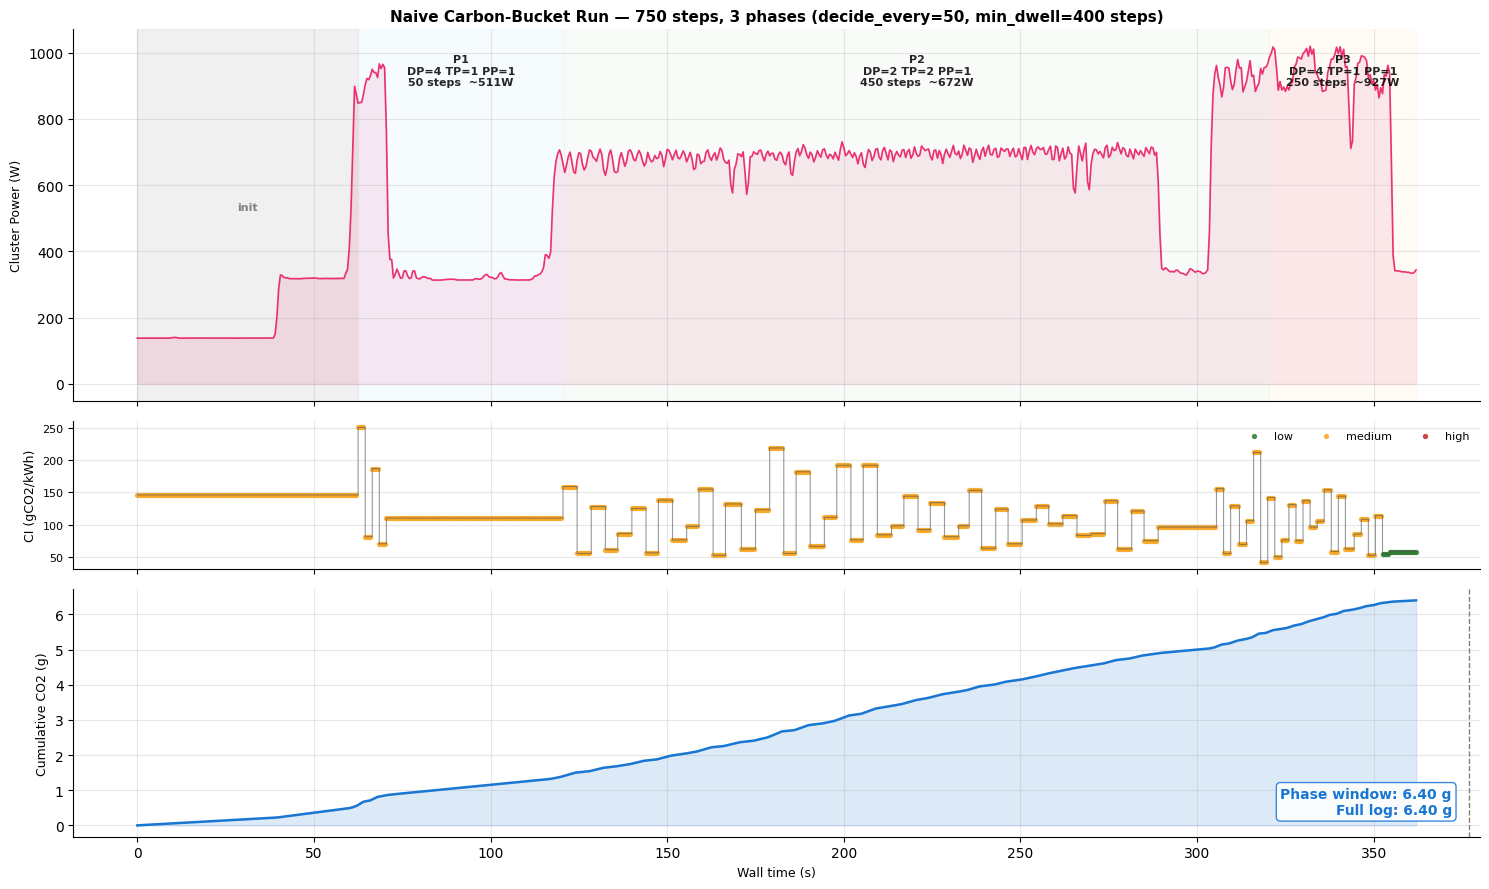

In [19]:
# naive run 3-panel plot using actual PowerMonitor CSV
fig, (ax1, ax2, ax3) = plt.subplots(
    3, 1, figsize=(15, 9), sharex=True,
    gridspec_kw={"height_ratios": [3, 1.2, 2]},
)

ax1.plot(wall_time, power, color=COLORS["schedule"], linewidth=1.2, alpha=0.9)
ax1.fill_between(wall_time, 0, power, alpha=0.12, color=COLORS["schedule"])
ax1.set_ylabel("Cluster Power (W)", fontsize=9)
ax1.set_title(
    f"Naive Carbon-Bucket Run — {results['total_steps']} steps, {len(phases)} phases "
    f"(decide_every={results['decide_every']}, min_dwell={MIN_DWELL_STEPS} steps)",
    fontsize=11, fontweight="bold",
)

if training_start_t > 0:
    ax1.axvspan(0, training_start_t, alpha=0.15, color="#9E9E9E")
    ax1.text(training_start_t / 2, ax1.get_ylim()[1] * 0.50, "init",
             ha="center", va="center", fontsize=8, fontweight="bold",
             color="#666", alpha=0.8)

phase_palette = ["#E3F2FD", "#E8F5E9", "#FFF3E0", "#F3E5F5", "#FCE4EC"]
for i, p in enumerate(phases):
    x0, x1 = phase_walls[i], min(phase_walls[i + 1], wall_time[-1])
    ax1.axvspan(x0, x1, alpha=0.30, color=phase_palette[i % len(phase_palette)])
    mid_x = (x0 + x1) / 2
    pow_obs = p.get("observed_power_w") or 0
    label = (
        f"P{i+1}\nDP={p['dp']} TP={p['tp']} PP={p['pp']}\n"
        f"{p['num_steps']} steps  ~{pow_obs:.0f}W"
    )
    ax1.text(mid_x, ax1.get_ylim()[1] * 0.93, label,
             ha="center", va="top", fontsize=8, fontweight="bold", alpha=0.85)

if run_end_t < wall_time[-1]:
    ax1.axvspan(run_end_t, wall_time[-1], alpha=0.12, color="#616161")
    ax1.text((run_end_t + wall_time[-1]) / 2, ax1.get_ylim()[1] * 0.35,
             "shutdown tail", ha="center", va="center", fontsize=8,
             color="#555", alpha=0.9)

bucket_colors = {"low": "#2E7D32", "medium": "#F9A825", "high": "#C62828"}
for b, color in bucket_colors.items():
    mask = bucket_trace == b
    ax2.scatter(wall_time[mask], ci_trace[mask], s=8, color=color, label=b, alpha=0.8)
ax2.step(wall_time, ci_trace, where="post", color="#555555", linewidth=0.8, alpha=0.6)
ax2.set_ylabel("CI (gCO2/kWh)", fontsize=9)
ax2.legend(frameon=False, fontsize=8, ncol=3, loc="upper right")
ax2.tick_params(labelsize=8)

ax3.plot(wall_time, cum_g, color="#1976D2", linewidth=1.8)
ax3.fill_between(wall_time, 0, cum_g, alpha=0.15, color="#1976D2")
ax3.axvline(run_end_t, color="#616161", linestyle="--", linewidth=1.0, alpha=0.8)
ax3.set_ylabel("Cumulative CO2 (g)", fontsize=9)
ax3.set_xlabel("Wall time (s)", fontsize=9)
ax3.text(0.98, 0.08,
         f"Phase window: {total_g_run_window:.2f} g\nFull log: {total_g_powerlog:.2f} g",
         transform=ax3.transAxes, ha="right", va="bottom",
         fontsize=10, fontweight="bold", color="#1976D2",
         bbox=dict(boxstyle="round", facecolor="white", edgecolor="#1976D2", alpha=0.85))

plt.tight_layout()
out = os.path.join(PLOTS_DIR, "graph_naive_elastic_run.png")
plt.savefig(out, dpi=150, bbox_inches="tight")
print(f"Saved: {out}")
plt.show()


### Naive Run 3-Panel Visualization

Power, carbon intensity, and cumulative carbon emissions with phase annotations.

In [20]:
# naive run summary
print("\n" + "=" * 90)
print("NAIVE CARBON-BUCKET ELASTIC RUN")
print("=" * 90)
print(f"  Run dir:            {NAIVE_RUN_DIR}")
print(f"  Power CSV:          {POWER_CSV}")
print(f"  Inner total wall:   {results['total_wall_s']:.1f}s "
      f"(training {results['total_train_s']:.1f}s, "
      f"reconfig {results['total_reconfig_s']:.1f}s, "
      f"checkpoint {results['total_save_s']:.1f}s)")
print(f"  Power log wall:     {n_samples * INTERVAL_SECONDS:.1f}s")
print(f"  Carbon phase win:   {total_g_run_window:.2f} gCO2 "
      f"(mean CI {ci_trace[run_mask].mean():.0f} g/kWh)")
print(f"  Carbon full log:    {total_g_powerlog:.2f} gCO2 "
      f"(includes launcher/shutdown tail)")
print(f"  Decision cadence:   every {results['decide_every']} steps")
print(f"  CI mapping:         {len(ci_values)} rows over {TOTAL_STEPS} steps "
      f"(progress-based, min_dwell={MIN_DWELL_STEPS} steps)")
print(f"  Phases scheduled:   {len(phases)}")

print(f"\n  {'Phase':<6} {'Bucket@start':<12} {'Config':<22} {'Steps':>8} "
      f"{'Train':>9} {'Iter':>11} {'P(W)':>8} {'Loss':>10}")
print("  " + "-" * 94)
for i, p in enumerate(phases):
    cfg_str = f"dp{p['dp']}_tp{p['tp']}_pp{p['pp']}"
    loss_s = f"{p['final_loss']:.4f}" if p.get("final_loss") else "N/A"
    pow_s = f"{p['observed_power_w']:.0f}" if p.get("observed_power_w") else "-"
    # Bucket the scheduler classified at the start of this phase, using
    # smoothed CI so the label matches what decide() returned.
    b0 = carbon_bucket(smoothed_ci_at_step(p["start_step"]))
    print(f"  {p['phase']:<6} {b0:<12} {cfg_str:<22} {p['num_steps']:>8} "
          f"{p['train_s']:>8.1f}s {p['avg_iter_ms']:>9.0f}ms/it "
          f"{pow_s:>8} {loss_s:>10}")



NAIVE CARBON-BUCKET ELASTIC RUN
  Run dir:            /afs/cs.pitt.edu/usr0/wat29/scheduling-carbon-aware-3d-parallelism/runs/naive_hybrid_local_20260509_213138
  Power CSV:          /afs/cs.pitt.edu/usr0/wat29/scheduling-carbon-aware-3d-parallelism/runs/naive_hybrid_local_20260509_213138/naive_elastic_gpt2_medium_power.csv
  Inner total wall:   314.5s (training 268.0s, reconfig 10.0s, checkpoint 36.5s)
  Power log wall:     362.5s
  Carbon phase win:   6.40 gCO2 (mean CI 113 g/kWh)
  Carbon full log:    6.40 gCO2 (includes launcher/shutdown tail)
  Decision cadence:   every 50 steps
  CI mapping:         720 rows over 750 steps (progress-based, min_dwell=400 steps)
  Phases scheduled:   3

  Phase  Bucket@start Config                    Steps     Train        Iter     P(W)       Loss
  ----------------------------------------------------------------------------------------------
  1      medium       dp4_tp1_pp1                  50     30.0s       601ms/it      511    10.9905
  2    

In [21]:
# ci bucket table for carbon_week.csv
n_rows = len(ci_values)
boundaries = np.ceil(np.arange(n_rows + 1) * TOTAL_STEPS / n_rows).astype(int)
ci_table = pd.DataFrame({
    "bucket_idx": np.arange(n_rows),
    "start_step": boundaries[:-1],
    "end_step": boundaries[1:] - 1,
    "carbon_g_per_kwh": ci_values,
})
ci_table["bucket"] = [carbon_bucket(c) for c in ci_table["carbon_g_per_kwh"]]
print(ci_table.to_string(index=False))


 bucket_idx  start_step  end_step  carbon_g_per_kwh bucket
          0           0         1             146.0   high
          1           2         2             165.0   high
          2           3         3             178.0   high
          3           4         4             185.0   high
          4           5         5             183.0   high
          5           6         6             186.0   high
          6           7         7             223.0   high
          7           8         8             237.0   high
          8           9         9             246.0   high
          9          10        10             251.0   high
         10          11        11             247.0   high
         11          12        12             239.0   high
         12          13        13             239.0   high
         13          14        14             193.0   high
         14          15        15             107.0 medium
         15          16        16              82.0 medi

Saved: /afs/cs.pitt.edu/usr0/wat29/scheduling-carbon-aware-3d-parallelism/plots/gpt2_medium_naive/graph_naive_ci_staircase.png


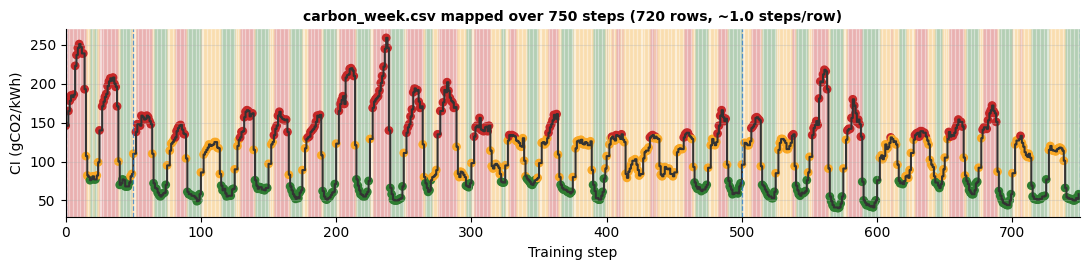

In [22]:
# staircase sanity check: progress-mapped carbon trace used by the naive run
fig, ax = plt.subplots(figsize=(11, 2.8))
for _, row in ci_table.iterrows():
    ax.axvspan(row["start_step"], row["end_step"] + 1,
               color=bucket_colors[row["bucket"]], alpha=0.12)
ax.step(ci_table["start_step"], ci_table["carbon_g_per_kwh"], where="post",
        color="#333333", linewidth=1.5)
ax.scatter(ci_table["start_step"], ci_table["carbon_g_per_kwh"],
           c=[bucket_colors[b] for b in ci_table["bucket"]], s=28)
# Phase boundaries in step space (where decide() actually switched configs).
for p in phases:
    ax.axvline(p["start_step"], color="#1976D2", linestyle="--",
               linewidth=0.9, alpha=0.7)
ax.axvline(phases[-1]["end_step"], color="#1976D2", linestyle="--",
           linewidth=0.9, alpha=0.7)
ax.set_title(
    f"carbon_week.csv mapped over {TOTAL_STEPS} steps "
    f"({len(ci_values)} rows, ~{TOTAL_STEPS / len(ci_values):.1f} steps/row)",
    fontsize=10, fontweight="bold",
)
ax.set_xlabel("Training step")
ax.set_ylabel("CI (gCO2/kWh)")
ax.set_xlim(0, TOTAL_STEPS)
plt.tight_layout()
out = os.path.join(PLOTS_DIR, "graph_naive_ci_staircase.png")
plt.savefig(out, dpi=150, bbox_inches="tight")
print(f"Saved: {out}")
plt.show()


### CI Schedule Staircase

Visualize the compressed carbon intensity schedule used by the naive scheduler.

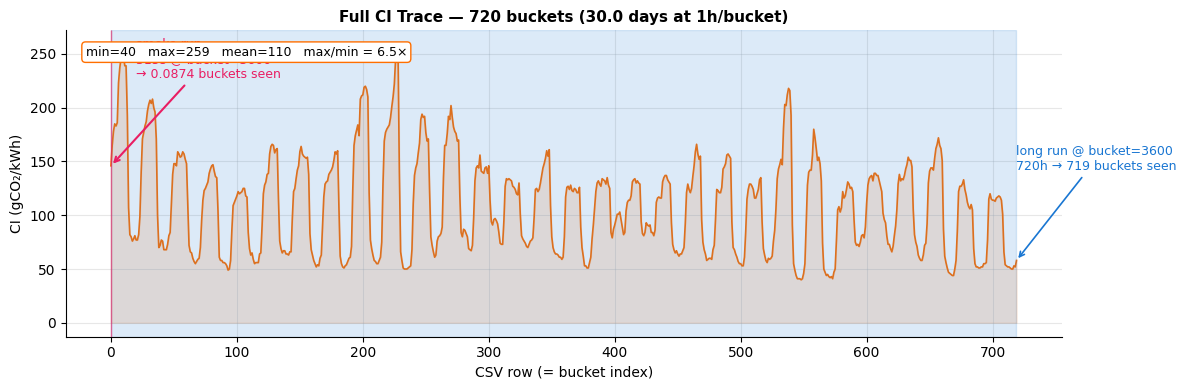

In [23]:
# figure 1 full
fig, ax = plt.subplots(figsize=(12, 4))
ci_csv = globals().get("ci_csv", globals().get("ci_values"))
if ci_csv is None:
    ci_csv = pd.read_csv(CARBON_CSV)["carbon"].to_numpy(dtype=float)
n_buckets = len(ci_csv)
hours = np.arange(n_buckets)
ax.plot(hours, ci_csv, color="#FF6F00", linewidth=1.2)
ax.fill_between(hours, 0, ci_csv, alpha=0.15, color="#FF6F00")

# smoke run window (in csv row units, given bucket=3600)
_results = globals().get("results", {})
_bucket_seconds = globals().get("BUCKET_SECONDS", 3600.0)
_ci_horizon_s = globals().get("CI_HORIZON_S", n_buckets * _bucket_seconds)
SMOKE_S = globals().get("SMOKE_S", _results.get("total_wall_s", 0.0))
SMOKE_BUCK = globals().get("SMOKE_BUCK", _bucket_seconds)
LONG_S = globals().get("LONG_S", _ci_horizon_s)
smoke_buckets = SMOKE_S / SMOKE_BUCK
ax.axvspan(0, smoke_buckets, color="#E91E63", alpha=0.6, zorder=3)
ax.annotate(
    f"smoke run\n{SMOKE_S:.0f}s @ bucket={SMOKE_BUCK:.0f}\n→ {smoke_buckets:.4f} buckets seen",
    xy=(smoke_buckets, ci_csv[0]), xytext=(20, ci_csv.max() * 0.88),
    fontsize=9, ha="left", color="#E91E63",
    arrowprops=dict(arrowstyle="->", color="#E91E63", lw=1.5),
)

# long run window at default bucket=3600
long_default_buckets = min(LONG_S / 3600.0, n_buckets - 1)
ax.axvspan(0, long_default_buckets, color="#1976D2", alpha=0.15, zorder=2)
ax.annotate(
    f"long run @ bucket=3600\n{LONG_S/3600:.0f}h → {long_default_buckets:.0f} buckets seen",
    xy=(long_default_buckets, ci_csv[int(long_default_buckets)]),
    xytext=(min(long_default_buckets + max(n_buckets * 0.25, 1), n_buckets - 1), ci_csv.max() * 0.55),
    fontsize=9, color="#1976D2",
    arrowprops=dict(arrowstyle="->", color="#1976D2", lw=1.2),
)

ax.set_xlabel("CSV row (= bucket index)", fontsize=10)
ax.set_ylabel("CI (gCO₂/kWh)", fontsize=10)
ax.set_title(f"Full CI Trace — {n_buckets} buckets ({n_buckets/24:.1f} days at 1h/bucket)",
             fontsize=11, fontweight="bold")
ax.text(0.02, 0.95,
        f"min={ci_csv.min():.0f}   max={ci_csv.max():.0f}   "
        f"mean={ci_csv.mean():.0f}   "
        f"max/min = {ci_csv.max()/ci_csv.min():.1f}×",
        transform=ax.transAxes, fontsize=9, va="top",
        bbox=dict(boxstyle="round", facecolor="white", edgecolor="#FF6F00"))
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "graph_ci_csv_full.png"),
            dpi=150, bbox_inches="tight")
plt.show()

def ci_staircase(t_grid, bucket_seconds, ci_values):
    """Create a staircase CI signal from bucketed CI values."""
    bucket_indices = np.floor(t_grid / bucket_seconds).astype(int)
    bucket_indices = np.clip(bucket_indices, 0, len(ci_values) - 1)
    return ci_values[bucket_indices]


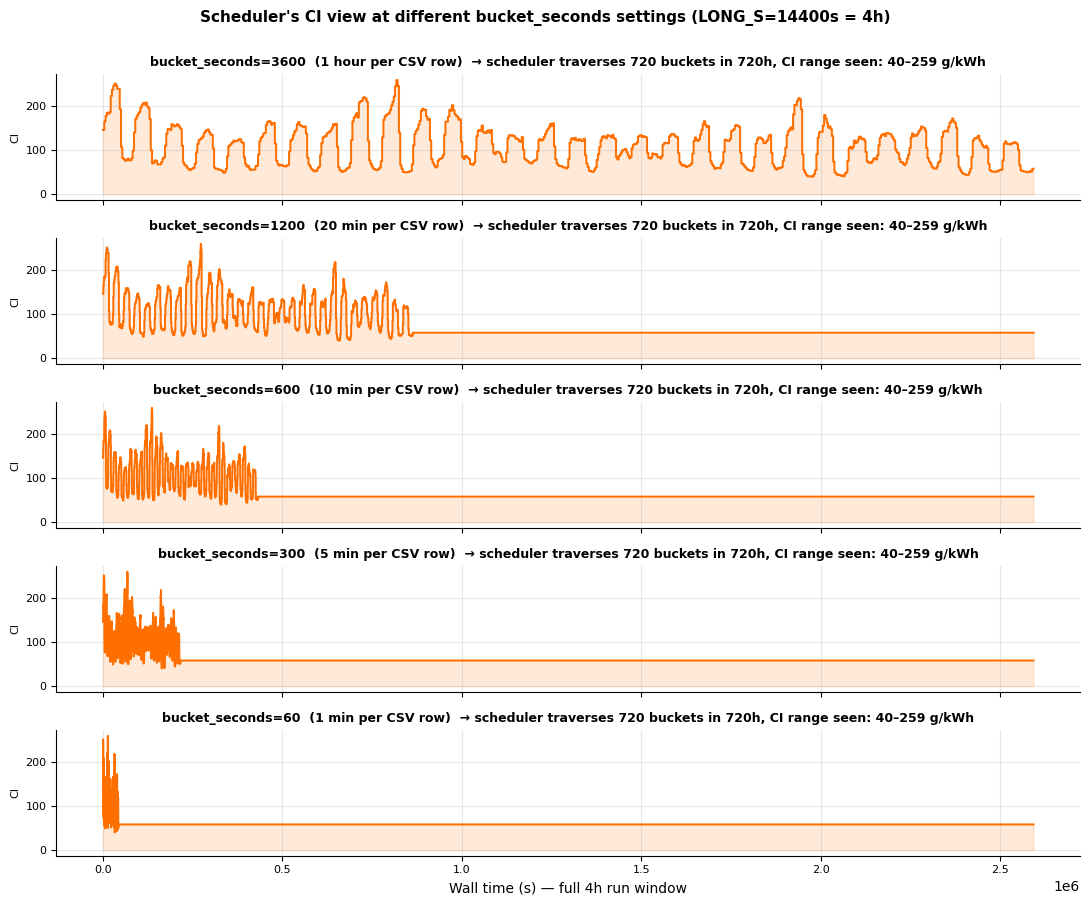

In [24]:
# figure 2 what
bucket_options = [3600, 1200, 600, 300, 60]
labels = {3600: "1 hour", 1200: "20 min", 600: "10 min",
          300: "5 min", 60: "1 min"}

fig, axes = plt.subplots(len(bucket_options), 1,
                          figsize=(11, 1.8 * len(bucket_options)),
                          sharex=True)
t_grid = np.arange(0, LONG_S, 1.0)   # 1-second resolution

for ax, b in zip(axes, bucket_options):
    seen = ci_staircase(t_grid, b, ci_csv)
    n_distinct = min(int(LONG_S / b) + 1, n_buckets)
    ax.step(t_grid, seen, where="post", color="#FF6F00", linewidth=1.4)
    ax.fill_between(t_grid, 0, seen, alpha=0.15,
                    color="#FF6F00", step="post")
    ax.set_title(
        f"bucket_seconds={b}  ({labels[b]} per CSV row)  "
        f"→ scheduler traverses {n_distinct} buckets in {LONG_S/3600:.0f}h, "
        f"CI range seen: {seen.min():.0f}–{seen.max():.0f} g/kWh",
        fontsize=9, fontweight="bold",
    )
    ax.set_ylabel("CI", fontsize=8)
    ax.tick_params(labelsize=8)

axes[-1].set_xlabel("Wall time (s) — full 4h run window", fontsize=10)
plt.suptitle("Scheduler's CI view at different bucket_seconds settings "
             "(LONG_S=14400s = 4h)",
             fontsize=11, fontweight="bold", y=1.00)
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "graph_ci_staircase_options.png"),
            dpi=150, bbox_inches="tight")
plt.show()


In [25]:
# summary
print("=" * 78)
print("CI TRACE ANALYSIS")
print("=" * 78)
print(f"  CSV:                {CARBON_CSV.split('/')[-1]}")
print(f"  Buckets:            {n_buckets} rows  ({n_buckets/24:.1f} days at 1h/bucket)")
print(f"  CI range:           {ci_csv.min():.0f} – {ci_csv.max():.0f} g/kWh "
      f"(max/min = {ci_csv.max()/ci_csv.min():.2f}×)")
print()
print(f"  Smoke run experience ({SMOKE_S:.0f}s @ bucket={SMOKE_BUCK:.0f}):")
print(f"    Saw {smoke_buckets:.4f} buckets → flat CI ≈ {ci_csv[0]:.0f}")
print(f"    Switch decision was driven by E_strat alone, not CI variation.")
print()
print(f"  Planned 4h comparison run:")
for b in bucket_options:
    n_seen = min(int(LONG_S / b) + 1, n_buckets)
    seen   = ci_csv[:n_seen]
    print(f"    bucket={b:>5} ({labels[b]:>8}):  "
          f"{n_seen:>3} buckets, CI {seen.min():.0f}–{seen.max():.0f} g/kWh, "
          f"max/min = {seen.max()/seen.min():.2f}×")
print()
print("  RECOMMENDATION for the long run:")
print("    --bucket-seconds 600   (10-min buckets → 24 buckets in 4h = 1 day of CI)")
print("    Decisions every ~200s (decide_every=1000 × τ≈0.2s) line up with")
print("    bucket changes every 600s — scheduler reacts to CI ~3× per bucket.")
print("=" * 78)

CI TRACE ANALYSIS
  CSV:                carbon_week.csv
  Buckets:            720 rows  (30.0 days at 1h/bucket)
  CI range:           40 – 259 g/kWh (max/min = 6.47×)

  Smoke run experience (315s @ bucket=3600):
    Saw 0.0874 buckets → flat CI ≈ 146
    Switch decision was driven by E_strat alone, not CI variation.

  Planned 4h comparison run:
    bucket= 3600 (  1 hour):  720 buckets, CI 40–259 g/kWh, max/min = 6.47×
    bucket= 1200 (  20 min):  720 buckets, CI 40–259 g/kWh, max/min = 6.47×
    bucket=  600 (  10 min):  720 buckets, CI 40–259 g/kWh, max/min = 6.47×
    bucket=  300 (   5 min):  720 buckets, CI 40–259 g/kWh, max/min = 6.47×
    bucket=   60 (   1 min):  720 buckets, CI 40–259 g/kWh, max/min = 6.47×

  RECOMMENDATION for the long run:
    --bucket-seconds 600   (10-min buckets → 24 buckets in 4h = 1 day of CI)
    Decisions every ~200s (decide_every=1000 × τ≈0.2s) line up with
    bucket changes every 600s — scheduler reacts to CI ~3× per bucket.


In [26]:
# short carbon viz
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors

plt.rcParams.update({
    "font.family": "sans-serif", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
})


In [27]:
# ── 3-config comparison: hybrid vs static baselines ──────────
import os, json, numpy as np, pandas as pd, matplotlib.pyplot as plt

TAG = "local_20260509_215822"   # or pull from globals()/env if you want it auto

ci_values_cmp = pd.read_csv(CARBON_CSV)["carbon"].to_numpy(dtype=float)

def load_run(kind):
    rd  = os.path.join(BASE, "runs", f"{kind}_{TAG}")
    pwr = load_power_csv(os.path.join(rd, f"naive_elastic_{MODEL_NAME}_power.csv"))
    res = json.load(open(os.path.join(rd, "elastic_results.json")))
    phases = json.load(open(os.path.join(rd, "phases.json")))

    p   = pwr["total_power_W"].to_numpy(dtype=float)
    ts  = pwr["time_step"].to_numpy()
    wt  = np.arange(len(p)) * INTERVAL_SECONDS

    total_steps = int(res["total_steps"])
    n_rows      = len(ci_values_cmp)
    # Same progress-based mapping the scheduler uses.
    idx   = np.clip((ts.astype(float) / max(total_steps, 1) * n_rows).astype(int),
                    0, n_rows - 1)
    ci    = ci_values_cmp[idx]
    cum, total_g = compute_carbon(p, ci, INTERVAL_SECONDS)

    return {
        "name":       kind,
        "wall_time":  wt,
        "power":      p,
        "ci":         ci,           # ← NEW
        "cum_g":      cum,
        "total_g":    total_g,
        "wall_s":     res["total_wall_s"],
        "train_s":    res["total_train_s"],
        "save_s":     res["total_save_s"],
        "phases":     phases,
        "avg_pow":    np.mean(p),
    }

runs = {kind: load_run(kind) for kind in ("naive_hybrid", "static_a", "static_b")}

# ── Headline table ───────────────────────────────────────────
print(f"{'config':<14} {'wall_s':>8} {'train_s':>8} {'save_s':>8} "
      f"{'phases':>8} {'avg_W':>8} {'CO2_g':>10}")
print("-" * 70)
for k, r in runs.items():
    print(f"{r['name']:<14} {r['wall_s']:>8.1f} {r['train_s']:>8.1f} "
          f"{r['save_s']:>8.1f} {len(r['phases']):>8d} "
          f"{r['avg_pow']:>8.0f} {r['total_g']:>10.2f}")

# Hybrid wins/losses vs each static
hyb = runs["naive_hybrid"]
for s in ("static_a", "static_b"):
    sb = runs[s]
    co2_save = (1 - hyb["total_g"]/sb["total_g"]) * 100
    wall_pen = (hyb["wall_s"]/sb["wall_s"] - 1) * 100
    print(f"\nhybrid vs {s}:  CO2 {co2_save:+.1f}%   wall {wall_pen:+.1f}%")

# ── Comparison plot (3 panels: power / CI / cumulative CO2) ──
fig, axes = plt.subplots(3, 1, figsize=(11, 8.5), sharex=True,
                         gridspec_kw={"height_ratios": [2, 1.2, 1.5]})
ax_pow, ax_ci, ax_cum = axes
colors = {"naive_hybrid": "#7B1FA2", "static_a": "#1976D2", "static_b": "#F57C00"}

# Power
for k, r in runs.items():
    c = colors[k]
    ax_pow.plot(r["wall_time"], r["power"], color=c, linewidth=0.8,
                alpha=0.6, label=f"{r['name']} ({r['avg_pow']:.0f}W avg)")
ax_pow.set_ylabel("Cluster Power (W)", fontsize=9)
ax_pow.legend(frameon=False, fontsize=8, loc="upper right")
ax_pow.set_title(
    f"3-config comparison — {hyb['phases'][0].get('num_steps') or '?'}+ steps, "
    f"min_dwell={MIN_DWELL_STEPS}",
    fontsize=11, fontweight="bold",
)
ax_pow.grid(alpha=0.3)

# CI (carbon schedule each run experienced — same trace, mapped by each run's
# step→wall-time profile, so the static_a line is more compressed than hybrid)
for k, r in runs.items():
    c = colors[k]
    ax_ci.plot(r["wall_time"], r["ci"], color=c, linewidth=1.0, alpha=0.85,
               label=f"{r['name']}  end @ {r['wall_s']:.0f}s")
ax_ci.set_ylabel("CI (gCO2/kWh)", fontsize=9)
ax_ci.legend(frameon=False, fontsize=8, loc="upper right")
ax_ci.tick_params(labelsize=8)
ax_ci.grid(alpha=0.3)

# Cumulative CO2
for k, r in runs.items():
    c = colors[k]
    ax_cum.plot(r["wall_time"], r["cum_g"], color=c, linewidth=2.0,
                label=f"{r['name']}: {r['total_g']:.2f}g")
ax_cum.set_xlabel("Wall time (s)", fontsize=9)
ax_cum.set_ylabel("Cumulative CO2 (g)", fontsize=9)
ax_cum.legend(frameon=False, fontsize=8, loc="upper left")
ax_cum.grid(alpha=0.3)

plt.tight_layout()
out = os.path.join(PLOTS_DIR, "graph_3way_comparison.png")
plt.savefig(out, dpi=150, bbox_inches="tight")
print(f"\nSaved: {out}")
plt.show()

FileNotFoundError: [Errno 2] No such file or directory: '/afs/cs.pitt.edu/usr0/wat29/scheduling-carbon-aware-3d-parallelism/runs/static_a_local_20260509_215822/naive_elastic_gpt2_medium_power.csv'